# Online Shoppers Purchasing Intention

**Задача:** исследовать данные посещений интернет-магазина и возможные сложности прогнозирования покупки (`Revenue`) по признакам текущей сессии.

**Источник:** [UCI Online Shoppers Purchasing Intention](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset), файл `online_shoppers_intention.csv`. CSV должен лежать рядом с ноутбуком. Библиотеки: `pandas`, `matplotlib`, `seaborn`.

## 1. Таблица

Размер, типы признаков, первые строки и сводная статистика.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
df = pd.read_csv("online_shoppers_intention.csv")
print("Размер:", df.shape)
print("Типы:", df.dtypes.value_counts().to_dict())
display(df.head())

Размер: (12330, 18)
Типы: {dtype('int64'): 7, dtype('float64'): 7, <StringDtype(storage='python', na_value=nan)>: 2, dtype('bool'): 2}


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [2]:
display(df.describe(include="all").T.round(2))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


В таблице 12 330 строк, 18 столбцов: 17 входных признаков и таргет `Revenue`. По смыслу среди входных признаков 10 числовых измерений и 7 категориальных признаков, включая коды устройств, региона и источника трафика.

## 2. Таргет

`Revenue` показывает, завершилась ли сессия покупкой (`True`).

Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    84.53
True     15.47
Name: proportion, dtype: float64


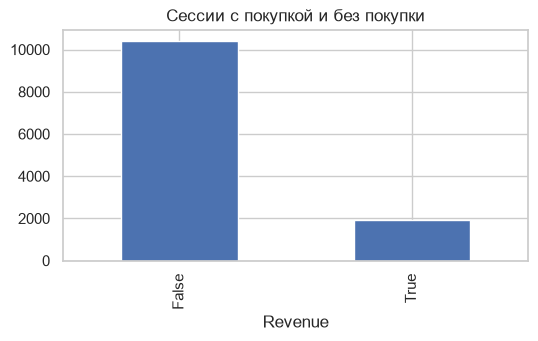

In [3]:
print(df["Revenue"].value_counts())
print((df["Revenue"].value_counts(normalize=True) * 100).round(2))
df["Revenue"].value_counts().reindex([False, True]).plot.bar(figsize=(6, 3))
plt.title("Сессии с покупкой и без покупки")
plt.xlabel("Revenue")
plt.show()

Покупкой завершились 1 908 сессий (15,47%), без покупки - 10 422 (84,53%). Исходная задача - бинарная классификация. Прогноз `False` для всех строк дал бы accuracy 84,53%.

## 3. Пропуски и дубликаты

Проверяются формальные `NaN`, полные повторы строк и повторы входных признаков.

In [4]:
print("NaN всего:", int(df.isna().sum().sum()))
print("Признаков с NaN:", int(df.isna().any().sum()))
print("Полных дубликатов:", int(df.duplicated().sum()))
print("Повторов входных признаков:", int(df.drop(columns="Revenue").duplicated().sum()))
print("Отдельного идентификатора сессии нет")

NaN всего: 0
Признаков с NaN: 0
Полных дубликатов: 125
Повторов входных признаков: 125
Отдельного идентификатора сессии нет


Формальных пропусков нет. Обнаружены 125 повторов строк, в том числе 125 повторов сочетания входных признаков. Отдельного идентификатора посетителя или сессии нет, поэтому совпадающие строки не позволяют установить, относятся ли записи к одному визиту.

## 4. Диапазоны, нули и распределения

Проверяются диапазоны показателей и согласованность числа посещённых страниц с длительностью их просмотра.

In [5]:
continuous = ["Administrative", "Administrative_Duration", "Informational",
              "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
              "BounceRates", "ExitRates", "PageValues", "SpecialDay"]
print("Отрицательные значения:", int(df[continuous].lt(0).sum().sum()))
for col in ["BounceRates", "ExitRates", "SpecialDay"]:
    print(col, "минимум:", df[col].min(), "максимум:", df[col].max())
print("Нулевые значения, %:")
display((100 * df[continuous].eq(0).mean()).round(2).rename("Нулей, %"))

Отрицательные значения: 0
BounceRates минимум: 0.0 максимум: 0.2
ExitRates минимум: 0.0 максимум: 0.2
SpecialDay минимум: 0.0 максимум: 1.0
Нулевые значения, %:


Administrative             46.78
Administrative_Duration    47.88
Informational              78.66
Informational_Duration     80.49
ProductRelated              0.31
ProductRelated_Duration     6.12
BounceRates                44.75
ExitRates                   0.62
PageValues                 77.86
SpecialDay                 89.85
Name: Нулей, %, dtype: float64

In [6]:
for count, duration in [("Administrative", "Administrative_Duration"),
                        ("Informational", "Informational_Duration"),
                        ("ProductRelated", "ProductRelated_Duration")]:
    print(count, "0 страниц при положительной длительности:",
          int(((df[count] == 0) & (df[duration] > 0)).sum()),
          "| посещения при нулевой длительности:",
          int(((df[count] > 0) & (df[duration] == 0)).sum()))

Administrative 0 страниц при положительной длительности: 0 | посещения при нулевой длительности: 135
Informational 0 страниц при положительной длительности: 0 | посещения при нулевой длительности: 226
ProductRelated 0 страниц при положительной длительности: 0 | посещения при нулевой длительности: 717


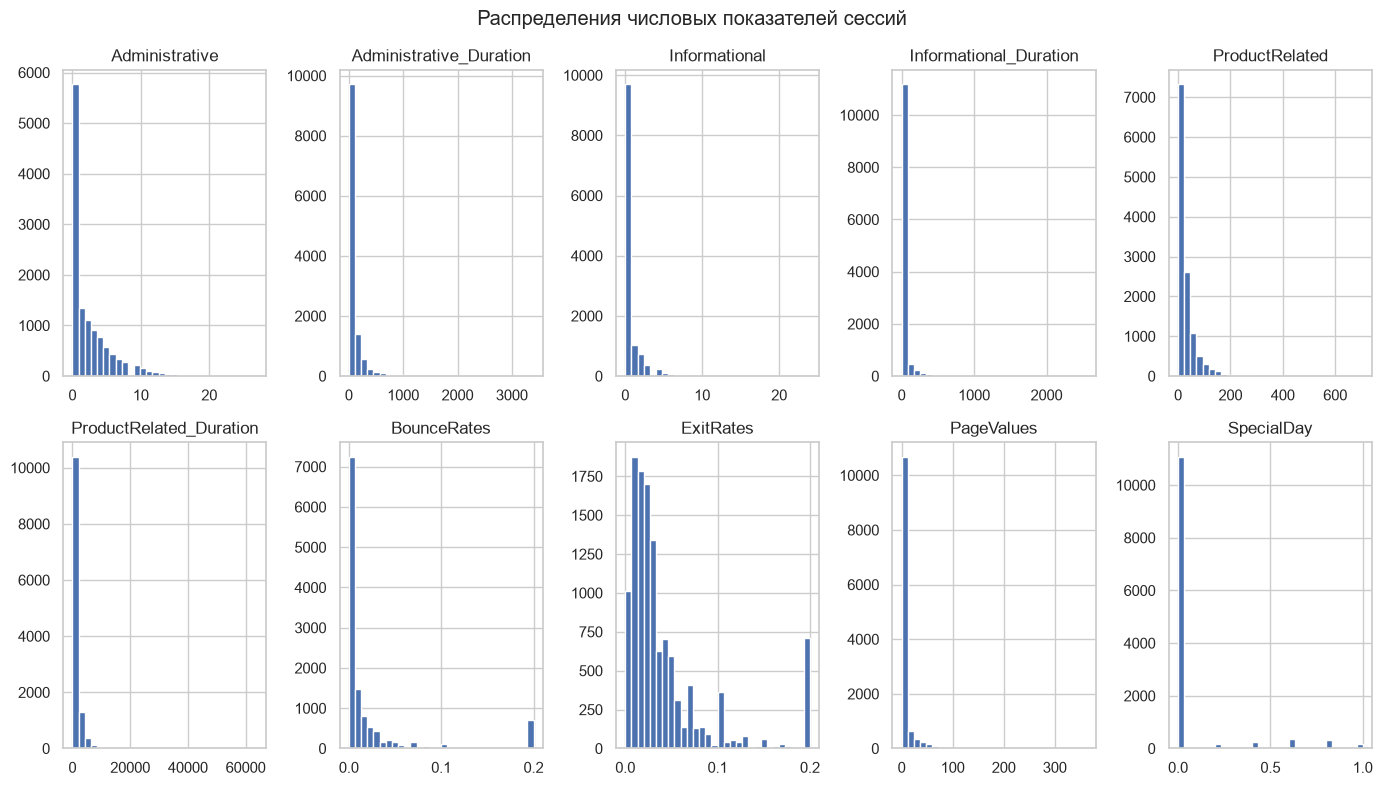

In [7]:
df[continuous].hist(bins=30, figsize=(14, 8), layout=(2, 5))
plt.suptitle("Распределения числовых показателей сессий")
plt.tight_layout()
plt.show()

Отрицательных значений у исследованных числовых показателей нет. `BounceRates` и `ExitRates` находятся в пределах 0–0,2, `SpecialDay` - в пределах 0–1. У `PageValues` нули составляют 77,86%, у `SpecialDay` - 89,85%. При нулевом числе посещённых страниц положительной длительности нет. Встречаются посещённые страницы с нулевой длительностью: 135 для `Administrative`, 226 для `Informational`, 717 для `ProductRelated`.

## 5. Потенциальные выбросы

Метод IQR применяется к выбранным количественным признакам. Для `PageValues` квартильный размах равен нулю, поэтому его нули и положительные значения исследуются отдельно.

In [8]:
for col in ["ProductRelated", "ProductRelated_Duration", "Administrative_Duration"]:
    s = df[col]
    q1, q3 = s.quantile([0.25, 0.75])
    flag = s.lt(q1 - 1.5 * (q3-q1)) | s.gt(q3 + 1.5 * (q3-q1))
    print(col, "медиана:", round(s.median(), 2),
          "IQR-сигналы:", int(flag.sum()), f"({100 * flag.mean():.2f}% строк)")
print("PageValues: Q1 =", df["PageValues"].quantile(.25),
      ", Q3 =", df["PageValues"].quantile(.75))

ProductRelated медиана: 18.0 IQR-сигналы: 987 (8.00% строк)
ProductRelated_Duration медиана: 598.94 IQR-сигналы: 961 (7.79% строк)
Administrative_Duration медиана: 7.5 IQR-сигналы: 1172 (9.51% строк)
PageValues: Q1 = 0.0 , Q3 = 0.0


IQR отмечает 987 значений `ProductRelated` (8,00%), 961 значение `ProductRelated_Duration` (7,79%) и 1 172 значения `Administrative_Duration` (9,51%). Это необычно большие числа страниц или длительности, не установленные ошибки. Для `PageValues` IQR не использовался.

## 6. Категориальные признаки и связь с таргетом

В `OperatingSystems`, `Browser`, `Region`, `TrafficType` целочисленные значения обозначают категории, а не непрерывные измерения. Для каждой группы вычисляются размер и доля сессий с покупкой.

In [9]:
categories = ["Month", "OperatingSystems", "Browser", "Region",
              "TrafficType", "VisitorType", "Weekend"]
for col in categories:
    summary = df.groupby(col)["Revenue"].agg(["size", "mean"])
    summary.columns = ["Строк", "Доля покупок"]
    summary["Доля покупок"] = (100 * summary["Доля покупок"]).round(2)
    print(col, "категорий:", len(summary))
    display(summary.sort_values("Строк", ascending=False))

Month категорий: 10


,Строк,Доля покупок
Month,,
May,3364,10.85
Nov,2998,25.35
Mar,1907,10.07
Dec,1727,12.51
Oct,549,20.95
Sep,448,19.20
Aug,433,17.55
Jul,432,15.28
June,288,10.07


OperatingSystems категорий: 8


,Строк,Доля покупок
OperatingSystems,,
2,6601,17.50
1,2585,14.66
3,2555,10.49
4,478,17.78
8,79,21.52
6,19,10.53
7,7,14.29
5,6,16.67


Browser категорий: 13


,Строк,Доля покупок
Browser,,
2,7961,15.36
1,2462,14.83
4,736,17.66
5,467,18.42
6,174,11.49
10,163,19.63
8,135,15.56
3,105,4.76
13,61,26.23


... (4 outputs left out)

VisitorType категорий: 3


,Строк,Доля покупок
VisitorType,,
Returning_Visitor,10551,13.93
New_Visitor,1694,24.91
Other,85,18.82


Weekend категорий: 2


,Строк,Доля покупок
Weekend,,
False,9462,14.89
True,2868,17.40


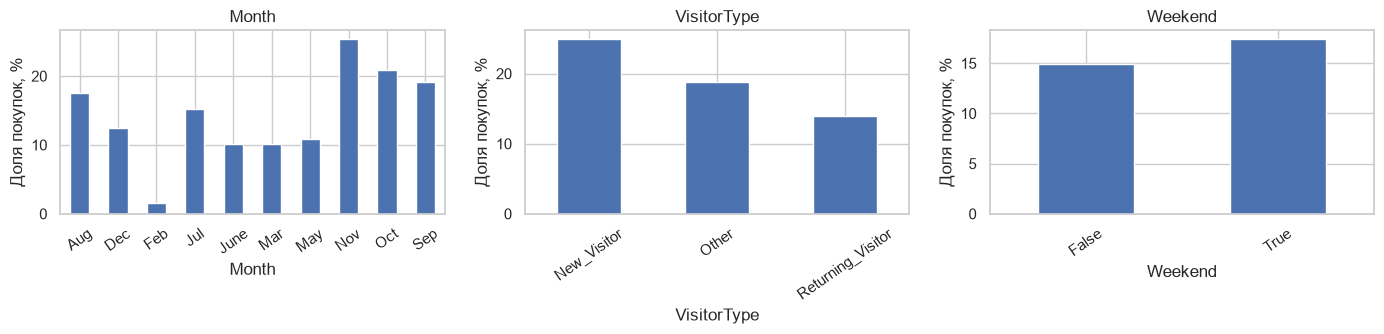

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["Month", "VisitorType", "Weekend"]):
    (100 * df.groupby(col)["Revenue"].mean()).plot.bar(ax=ax)
    ax.set_title(col)
    ax.set_ylabel("Доля покупок, %")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

По `Month` доля покупок составляет 1,63% в феврале (184 сессии) и 25,35% в ноябре (2 998 сессий). У новых посетителей - 24,91% (1 694 сессии), у возвращающихся - 13,93% (10 551 сессия). В выходные - 17,40%, в будни - 14,89%. Категории `Browser` и `TrafficType` включают группы с единичными наблюдениями.

## 7. Числовые признаки и корреляции

Сравниваются значения показателей по классам и попарные линейные корреляции.

In [11]:
print("Медианы по Revenue:")
display(df.groupby("Revenue")[continuous].median().T.round(2))
print("Средние по Revenue:")
display(df.groupby("Revenue")[continuous].mean().T.round(2))

Медианы по Revenue:


Revenue,False,True
Administrative,0.00,2.00
Administrative_Duration,0.00,52.37
Informational,0.00,0.00
Informational_Duration,0.00,0.00
ProductRelated,16.00,29.00
ProductRelated_Duration,510.19,1109.91
BounceRates,0.00,0.00
ExitRates,0.03,0.02
PageValues,0.00,16.76
SpecialDay,0.00,0.00


Средние по Revenue:


Revenue,False,True
Administrative,2.12,3.39
Administrative_Duration,73.74,119.48
Informational,0.45,0.79
Informational_Duration,30.24,57.61
ProductRelated,28.71,48.21
ProductRelated_Duration,1069.99,1876.21
BounceRates,0.03,0.01
ExitRates,0.05,0.02
PageValues,1.98,27.26
SpecialDay,0.07,0.02


In [12]:
corr = df[continuous + ["Revenue"]].corr()
print("Корреляции с Revenue:")
display(corr["Revenue"].drop("Revenue").sort_values(ascending=False).round(3))
print("BounceRates и ExitRates:", round(corr.loc["BounceRates", "ExitRates"], 3))
print("ProductRelated и ProductRelated_Duration:",
      round(corr.loc["ProductRelated", "ProductRelated_Duration"], 3))

Корреляции с Revenue:


PageValues                 0.493
ProductRelated             0.159
ProductRelated_Duration    0.152
Administrative             0.139
Informational              0.095
Administrative_Duration    0.094
Informational_Duration     0.070
SpecialDay                -0.082
BounceRates               -0.151
ExitRates                 -0.207
Name: Revenue, dtype: float64

BounceRates и ExitRates: 0.913
ProductRelated и ProductRelated_Duration: 0.861


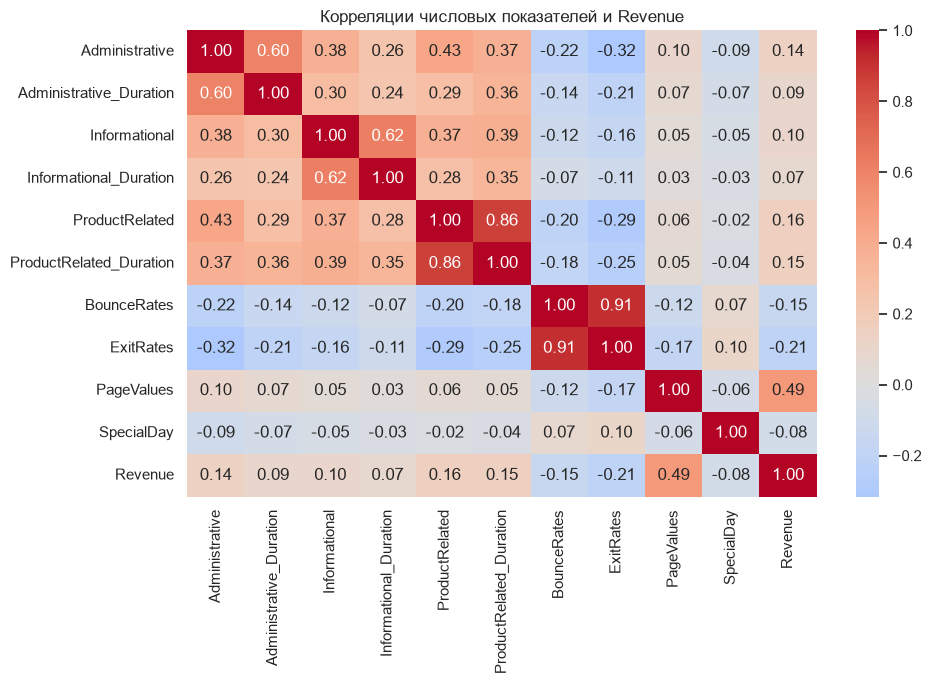

In [13]:
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции числовых показателей и Revenue")
plt.tight_layout()
plt.show()

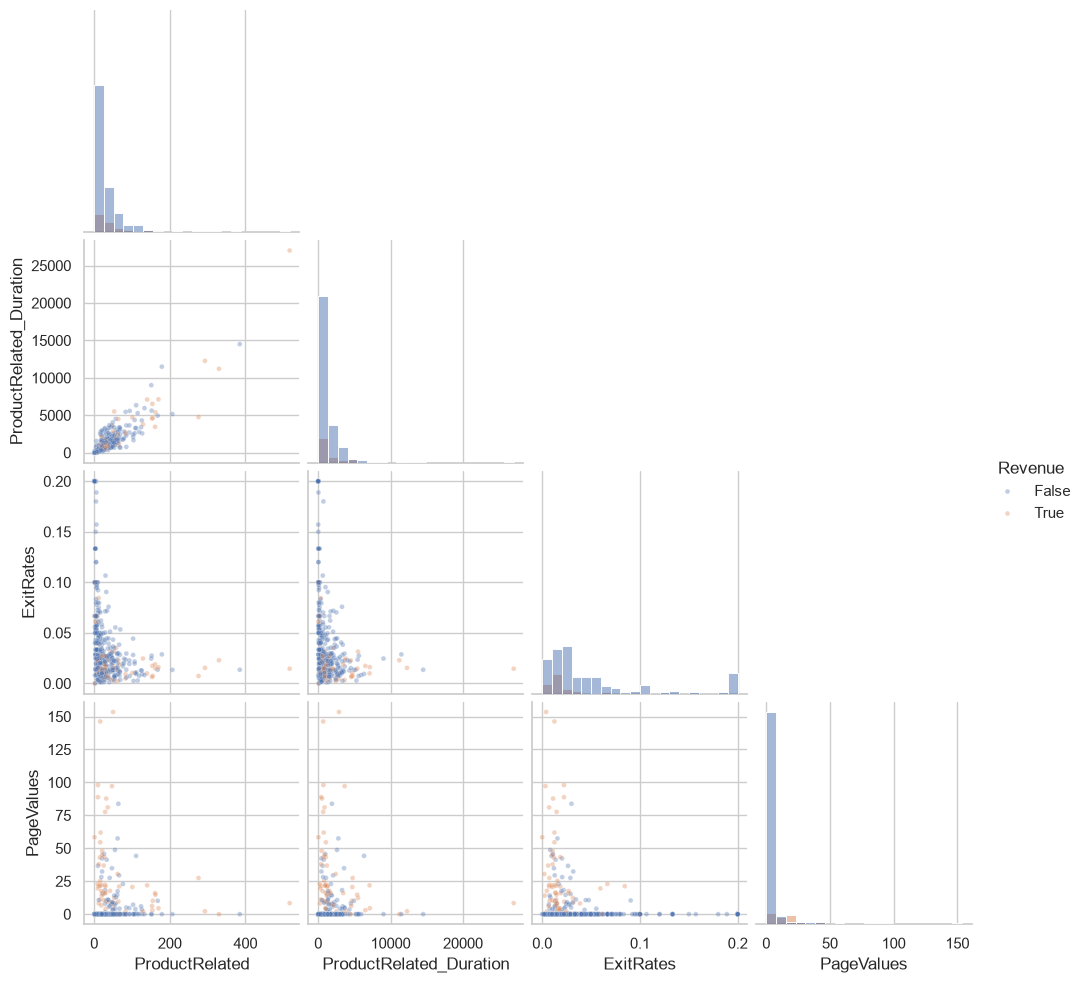

In [14]:
sample = df[["ProductRelated", "ProductRelated_Duration", "ExitRates",
             "PageValues", "Revenue"]].sample(n=450, random_state=42)
sns.pairplot(sample, hue="Revenue", corner=True, diag_kind="hist",
             plot_kws={"alpha": 0.35, "s": 12}, diag_kws={"bins": 20})
plt.show()

У покупок выше медиана `ProductRelated` (29 против 16), `ProductRelated_Duration` (1 109,91 против 510,19) и `PageValues` (16,76 против 0). Корреляция `PageValues` с `Revenue` - 0,493; `ExitRates` - −0,207. Сильно связаны также `BounceRates` и `ExitRates` (0,913), количество продуктовых страниц и длительность их просмотра (0,861).

## 8. Проверка `PageValues` и момента прогноза

Сравниваются доли покупок при нулевом и положительном `PageValues`. Отдельно учитывается, что агрегированные показатели сессии меняются по мере просмотра страниц.

In [15]:
for name, mask in [("PageValues = 0", df["PageValues"].eq(0)),
                   ("PageValues > 0", df["PageValues"].gt(0))]:
    print(name, "строк:", int(mask.sum()),
          "доля покупок, %:", round(100 * df.loc[mask, "Revenue"].mean(), 2))
print("Месяцы в файле:", sorted(df["Month"].unique().tolist()))
print("Дата и идентификатор посетителя в файле отсутствуют")

PageValues = 0 строк: 9600 доля покупок, %: 3.85
PageValues > 0 строк: 2730 доля покупок, %: 56.34
Месяцы в файле: ['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep']
Дата и идентификатор посетителя в файле отсутствуют


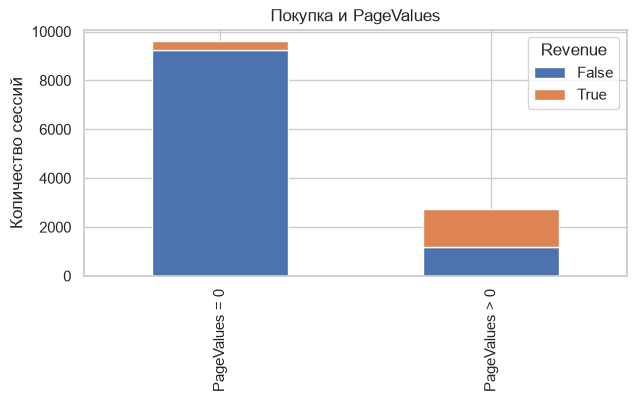

In [16]:
pd.DataFrame({"PageValues = 0": df.loc[df.PageValues.eq(0), "Revenue"].value_counts(),
              "PageValues > 0": df.loc[df.PageValues.gt(0), "Revenue"].value_counts()}).T.plot.bar(
    stacked=True, figsize=(7, 3.2))
plt.title("Покупка и PageValues")
plt.ylabel("Количество сессий")
plt.show()

При `PageValues = 0` покупкой завершились 3,85% из 9 600 сессий; при `PageValues > 0` - 56,34% из 2 730. По определению UCI `PageValues` основан на статистике страниц перед транзакциями. Для прогноза в реальном времени нужно уточнить способ его расчёта и доступность на выбранном этапе сессии. Количество посещённых страниц и суммарная длительность просмотра также зависят от момента прогноза. В файле есть 10 названий месяцев, но нет полной даты или идентификатора посетителя.

## 9. Выводы и эталон для агента

1. **Цель:** `Revenue`, покупка в текущей сессии. Постановка - бинарная классификация.
2. **Дисбаланс:** доля покупок 15,47%; одной accuracy недостаточно.
3. **Пропуски:** формальных `NaN` нет; выявлены 125 полных повторов строк.
4. **Признаки:** `OperatingSystems`, `Browser`, `Region`, `TrafficType` рассматривать как коды категорий.
5. **Выбросы:** не удалять большие значения посещённых страниц и длительностей по одному правилу IQR.
6. **Момент прогноза:** уточнить, в какой момент сессии формируется прогноз и какие показатели уже известны.
7. **Риск утечки:** проверить происхождение и доступность `PageValues`; высокая связь с `Revenue` сама по себе не подтверждает утечку.
8. **Метрика:** выбирать с учётом действия по прогнозу; рассматривать precision, recall, PR-AUC и затраты на ошибочные предложения.
9. **Валидация:** не объявлять случайное разбиение проверкой будущих периодов. Полных дат и идентификаторов сессий в файле нет.